ASSIGNMENT No: 09 
Title: Implement Agglomerative hierarchical clustering algorithm using appropriate dataset. 
Problem Statement: Implement Agglomerative hierarchical clustering algorithm using appropriate 
dataset

Step 1:Import Libraries and load the dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Load Credit Card dataset
X = pd.read_csv("CC_GENERAL (1).csv")

print("Dataset loaded successfully")
print("Shape:", X.shape)
print(X.head())

Dataset loaded successfully
Shape: (8950, 18)
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.

Step 2 — Preprocess the data

In [3]:
# Remove customer ID
X = X.drop("CUST_ID", axis=1)

# Convert all columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Handle missing values
X = X.ffill().bfill()

print("Missing values:", X.isnull().sum().sum())
print("Preprocessed data:")
print(X.head())

Missing values: 0
Preprocessed data:
       BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0    40.900749           0.818182      95.40              0.00   
1  3202.467416           0.909091       0.00              0.00   
2  2495.148862           1.000000     773.17            773.17   
3  1666.670542           0.636364    1499.00           1499.00   
4   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.083333   
1                    0.000000                  

Step 3 — Apply PCA

In [4]:
# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Normalization
X_normalized = normalize(X_scaled)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_normalized)

# Convert PCA result into DataFrame
X_principal = pd.DataFrame(
    X_pca,
    columns=["P1", "P2"]
)

print("PCA completed successfully")
print(X_principal.head())
print("PCA Shape:", X_principal.shape)

PCA completed successfully
         P1        P2
0 -0.489949 -0.679976
1 -0.519099  0.544827
2  0.330633  0.268879
3 -0.481656 -0.097611
4 -0.563512 -0.482506
PCA Shape: (8950, 2)


Step 4 — Create the dendrogram

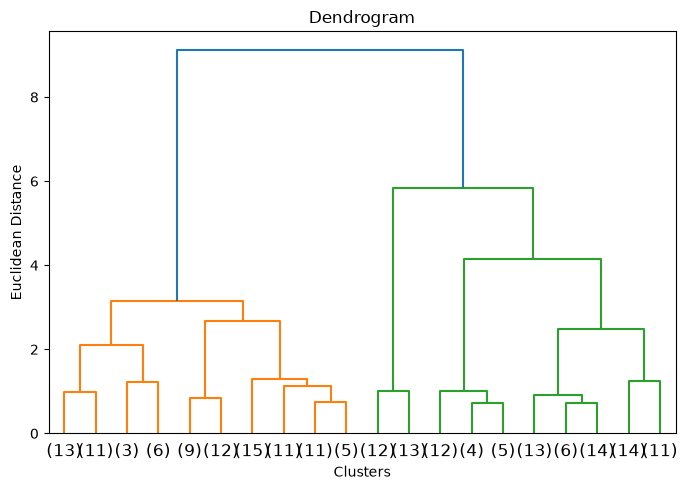

In [6]:
# Select sample for dendrogram
sample_data = X_principal.sample(
    n=min(200, len(X_principal)),
    random_state=42
)

# Calculate linkage
Z = shc.linkage(
    sample_data.to_numpy(),
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(7, 5))

shc.dendrogram(
    Z,
    truncate_mode="lastp",
    p=20
)

plt.title("Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Euclidean Distance")

plt.tight_layout()
plt.show()

Step 5 — Apply Agglomerative Clustering

In [7]:
# Create models for different numbers of clusters
models = {}

for k in range(2, 7):
    models[k] = AgglomerativeClustering(n_clusters=k)

# Perform clustering with 2 clusters
labels = models[2].fit_predict(X_principal)

print("Agglomerative clustering completed")
print("Number of clusters: 2")
print("Cluster labels:")
print(labels)

Agglomerative clustering completed
Number of clusters: 2
Cluster labels:
[0 0 1 ... 1 0 0]


Step 6 — Visualize the clusters

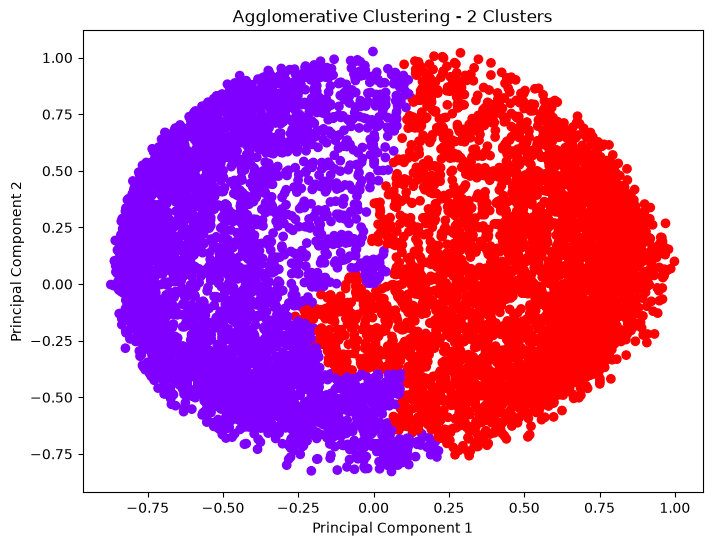

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_principal["P1"],
    X_principal["P2"],
    c=labels,
    cmap="rainbow"
)

plt.title("Agglomerative Clustering - 2 Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

Step 7 — Calculate Silhouette Scores

In [10]:
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []

for k in k_values:

    model = AgglomerativeClustering(n_clusters=k)

    labels = model.fit_predict(X_principal)

    score = silhouette_score(
        X_principal,
        labels
    )

    silhouette_scores.append(score)

# Display scores
print("Silhouette Scores:")

for k, score in zip(k_values, silhouette_scores):
    print(f"{k} Clusters: {score:.4f}")

Silhouette Scores:
2 Clusters: 0.4324
3 Clusters: 0.4278
4 Clusters: 0.3747
5 Clusters: 0.3551
6 Clusters: 0.3169


Step 8 — Find the optimal number of clusters

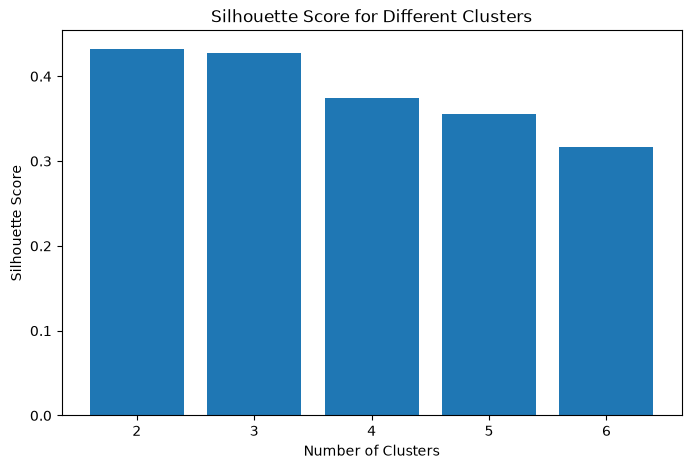

Optimal Number of Clusters: 2


In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    k_values,
    silhouette_scores
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Clusters")

plt.show()

# Find best cluster count
best_k = k_values[np.argmax(silhouette_scores)]

print("Optimal Number of Clusters:", best_k)

In [12]:
# ==============================================================================
# CODE EXPLANATION
# ==============================================================================
# 1. Data Loading & Cleaning:
#    - Loads 'CC_GENERAL (1).csv' (8,950 customer records, 18 features).
#    - Drops 'CUST_ID' because unique IDs carry no behavioral patterns.
#    - Converts all 17 remaining columns to numeric and fills missing values
#      (e.g., in 'MINIMUM_PAYMENTS') using forward-fill (ffill) + backward-fill (bfill).
#
# 2. Feature Scaling & Normalization:
#    - StandardScaler(): Centers features to mean=0 and std=1 so large-scale
#      features (like BALANCE or CREDIT_LIMIT) do not dominate distances.
#    - normalize(): Scales each customer row vector to unit L2 norm so clustering
#      focuses on relative spending proportions rather than raw magnitude.
#
# 3. Dimensionality Reduction (PCA):
#    - PCA(n_components=2): Projects the 17 normalized features into 2 orthogonal
#      components (P1 and P2) to reduce computation cost and enable 2D plotting.
#
# 4. Dendrogram Construction:
#    - Samples 200 rows (random_state=42) to keep the dendrogram readable and fast.
#    - linkage(..., method="ward"): Merges cluster pairs that cause the minimum
#      increase in total within-cluster variance.
#    - Truncated dendrogram (p=20) shows the tallest vertical Euclidean distance
#      jump at the top, visually confirming k = 2 as the optimal split.
#
# 5. Agglomerative Clustering & Silhouette Evaluation:
#    - Fits AgglomerativeClustering for k in {2, 3, 4, 5, 6}.
#    - Evaluates cluster quality using silhouette_score:
#        k = 2 -> 0.4324 (Optimal)
#        k = 3 -> 0.4278
#        k = 4 -> 0.3747
#        k = 5 -> 0.3551
#        k = 6 -> 0.3169
#    - Score peaks at k = 2 and drops monotonically afterward, confirming 2 clusters.

# ==============================================================================
# VIVA QUESTIONS & ANSWERS
# ==============================================================================
# Q1: What is Agglomerative Hierarchical Clustering, and how does it differ from K-Means?
# A1: It is a bottom-up hierarchical method where each data point starts as its own
#     cluster and pairs merge iteratively until one cluster remains. Unlike K-Means,
#     it does not require pre-specifying k to build the tree, is deterministic (no
#     random centroids), and produces a dendrogram.
#
# Q2: Why did you drop 'CUST_ID' before clustering?
# A2: 'CUST_ID' is an arbitrary unique identifier. Including it would introduce
#     artificial distance differences without reflecting actual customer behavior.
#
# Q3: Why are both StandardScaler and normalize applied before PCA?
# A3: StandardScaler equalizes feature variance across columns so high-range variables
#     do not dominate. normalize() scales each sample row to unit length, focusing
#     similarity on the directional pattern of customer spending across features.
#
# Q4: Why apply PCA before Agglomerative Clustering?
# A4: Hierarchical clustering has high time/memory complexity (O(n^3) time, O(n^2)
#     space). Reducing 17 features to 2 principal components (P1, P2) speeds up
#     distance calculations, removes noise/collinearity, and allows 2D visualization.
#
# Q5: What is Ward's linkage method in the dendrogram?
# A5: Ward's method merges the two clusters that result in the smallest increase in
#     total within-cluster sum of squared errors (variance), producing compact,
#     evenly sized spherical clusters.
#
# Q6: How do you find the optimal number of clusters from a dendrogram?
# A6: Find the tallest vertical line (largest Euclidean distance between merges) that
#     does not cross any horizontal merge line and draw a horizontal cut across it.
#     The number of vertical lines intersected equals optimal k (here, k = 2).
#
# Q7: What is the Silhouette Score, and why was k = 2 chosen?
# A7: Silhouette Score ranges from -1 to +1 and measures intra-cluster cohesion vs.
#     inter-cluster separation. Here, k = 2 gave the highest score (0.4324), while
#     scores decreased steadily from k = 3 to k = 6.
#
# Q8: Why sample 200 rows for the dendrogram instead of all 8,950 rows?
# A8: Plotting all 8,950 leaf nodes creates an unreadable, overly dense tree and is
#     computationally heavy. Sampling 200 rows (random_state=42) with truncation
#     keeps the cluster hierarchy clear and interpretable.